In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../cardio_train.csv", sep=";")
df = df.drop(columns=["id"])

In [3]:

print(df.shape)

(70000, 12)


#The original age variable is measured in days. so we divide it with 365 to have age in years :

In [4]:
df["age"] = df["age"] / 365.25

df.rename(
    columns={"age": "age_years"},
    inplace=True
)

C:\Users\monta\AppData\Local\Temp\ipykernel_97024\2297031971.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(


In [5]:
df.head()

,age_years,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,50.357290,2,168,62.0,110,80,1,1,0,0,1,0
1,55.381246,1,156,85.0,140,90,3,1,0,0,1,1
2,51.627652,1,165,64.0,130,70,3,1,0,0,0,1
3,48.249144,2,169,82.0,150,100,1,1,0,0,1,1
4,47.841205,1,156,56.0,100,60,1,1,0,0,0,0


In [6]:
# we create a feature BMI (Body Mass Index) uses weight and height.

In [7]:
df["bmi"] = (
    df["weight"] /
    (df["height"] / 100) ** 2
)

In [8]:
df.head()


,age_years,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,bmi
0,50.357290,2,168,62.0,110,80,1,1,0,0,1,0,21.967120
1,55.381246,1,156,85.0,140,90,3,1,0,0,1,1,34.927679
2,51.627652,1,165,64.0,130,70,3,1,0,0,0,1,23.507805
3,48.249144,2,169,82.0,150,100,1,1,0,0,1,1,28.710479
4,47.841205,1,156,56.0,100,60,1,1,0,0,0,0,23.011177


In [9]:
print(
    df[["ap_hi", "ap_lo"]]
    .describe(percentiles=[0.01, 0.05, 0.95, 0.99])
)

              ap_hi         ap_lo
count  70000.000000  70000.000000
mean     128.817286     96.630414
std      154.011419    188.472530
min     -150.000000    -70.000000
1%        90.000000     60.000000
5%       100.000000     70.000000
95%      160.000000    100.000000
99%      180.000000   1000.000000
max    16020.000000  11000.000000


In [10]:
invalid_bp = (
    (df["ap_hi"] <= 0) |
    (df["ap_lo"] <= 0) |
    (df["ap_hi"] <= df["ap_lo"]) |
    (df["ap_hi"] > 300) |
    (df["ap_lo"] > 200)
)

print("Invalid BP records:", invalid_bp.sum())

Invalid BP records: 1291


In [11]:
df = df[~invalid_bp].copy()

In [12]:
print(df.shape)

(68709, 13)


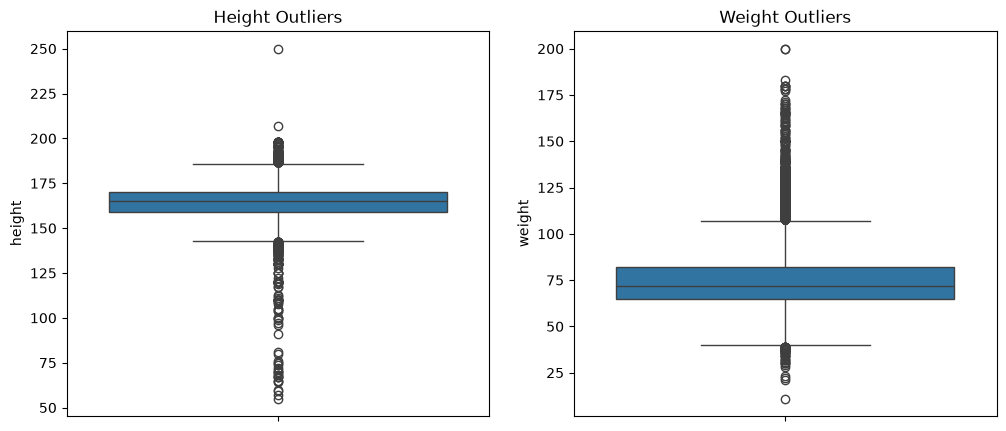

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["height"], ax=axes[0])
axes[0].set_title("Height Outliers")

sns.boxplot(y=df["weight"], ax=axes[1])
axes[1].set_title("Weight Outliers")

plt.show()
plt.show()

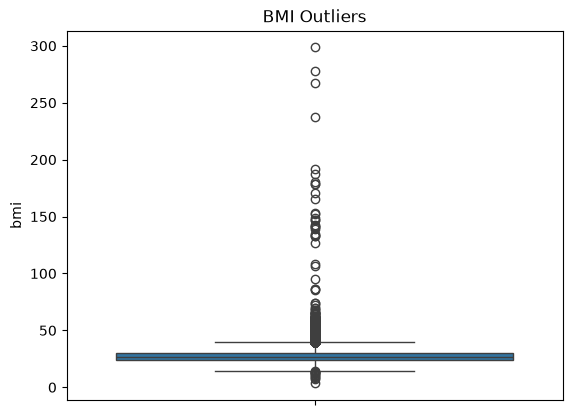

In [14]:
sns.boxplot(y=df["bmi"])
plt.title("BMI Outliers")
plt.show()

In [15]:
print(df["gender"].unique())
print(df["cholesterol"].unique())
print(df["gluc"].unique())
print(df["smoke"].unique())
print(df["alco"].unique())
print(df["active"].unique())
print(df["cardio"].unique())

[2 1]
[1 3 2]
[1 2 3]
[0 1]
[0 1]
[1 0]
[0 1]


In [16]:

columns = ["height", "weight", "bmi"]

df_clean = df.copy()
outlier_mask = pd.Series(False, index=df.index)

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask |= (df[col] < lower) | (df[col] > upper)

df_clean = df.loc[~outlier_mask].copy()

print("Original dataset:", len(df))
print("Cleaned dataset:", len(df_clean))
print("Removed observations:", outlier_mask.sum())
print("Remaining observations:", len(df_clean))

Original dataset: 68709
Cleaned dataset: 65674
Removed observations: 3035
Remaining observations: 65674


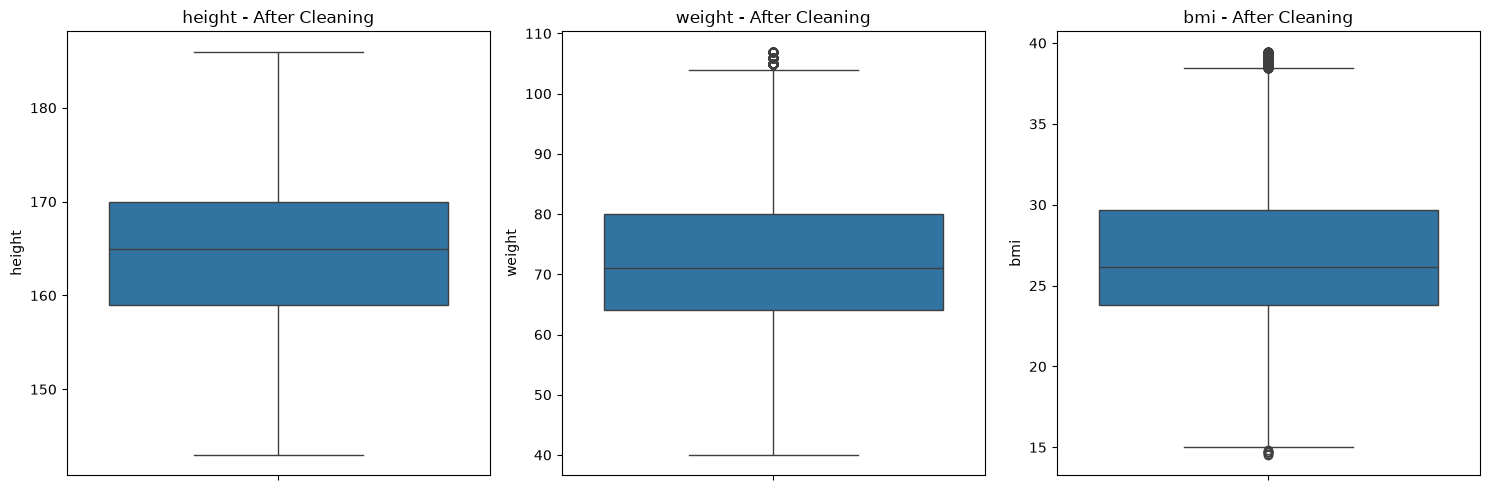

In [17]:
#visualize after cleaning 
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for col, ax in zip(columns, axes):
    sns.boxplot(y=df_clean[col], ax=ax)
    ax.set_title(f"{col} - After Cleaning")

plt.tight_layout()
plt.show()

In [18]:
df.to_csv(
    "../cardio_cleaned.csv",
    index=False
)

In [19]:
X = df.drop(columns=["cardio"])

y = df["cardio"]

In [20]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train ,y_test = train_test_split(
    X,
    y, test_size=0.2,
    random_state=42,
    stratify =y
)
print(X_train.shape)
print(X_test.shape)

(54967, 12)
(13742, 12)


In [21]:
#feature scaling 
#scaling the values in the data to  be values between 0 and 1 
from sklearn.preprocessing import StandardScaler
sc =StandardScaler()
X_train=sc.fit_transform(X_train)
X_test=sc.transform(X_test)

In [22]:
#feature encoding
#encoding the categorical values in the data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

cat_cols = [0]   # <-- index(es) of your categorical column(s)

oh = ColumnTransformer(
    transformers=[("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols)],
    remainder="passthrough"   # keep the numeric columns as they are
)

X_train = oh.fit_transform(X_train)   # learn categories from train only
X_test  = oh.transform(X_test)        # apply the same encoding to test

In [23]:
#use random forest classifier
from sklearn.ensemble import RandomForestClassifier
forest= RandomForestClassifier(n_estimators=10,random_state=42)
forest.fit(X_train,y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [24]:
from sklearn.linear_model import LogisticRegression
logistic = LogisticRegression(max_iter=1000, random_state=42)
logistic.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [ ]:
from sklearn.svm import SVC
svm = SVC(kernel="rbf", random_state=42)
svm.fit(X_train, y_train)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

In [ ]:
#evaluating models using evaluation metrics
from sklearn.metrics import accuracy_score, f1_score, recall_score, precision_score

models = {
    "Logistic Regression": logistic,
    "Random Forest":       forest,
    "SVM":                 svm,
    "Decision Tree":       tree,
}

for name, model in models.items():
    y_pred = model.predict(X_test)
    acc       = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    recall    = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1        = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    print(f"{name:20s} acc = {acc:.4f}  precision = {precision:.4f}  recall = {recall:.4f}  F1 = {f1:.4f}")